# Predicción de inasistencia a una cita médica

Este cuaderno reproduce el LightGBM que ordena las citas por riesgo antes de una revisión humana. Comenzamos con una referencia de 17 variables, incorporamos el historial disponible al día de la cita y medimos cuánto mejora la priorización. El identificador del paciente permite construir el historial y separar personas entre pliegues. Ambos estimadores reciben exclusivamente las variables declaradas en sus matrices.

Desde la raíz del proyecto, ejecuta todas las celdas con el entorno de `requirements.txt`. La única tabla de entrada es `data/citas_medicas_preprocesadas.csv`, que genera el cuaderno 02. Para reproducir la configuración publicada se necesita también `models/mejores_hiperparametros.json`. Las salidas son el modelo con sus categorías y umbrales y el resumen `models/metricas.json`.


In [1]:
from datetime import datetime
import json
from pathlib import Path
from tempfile import TemporaryDirectory

import joblib
import lightgbm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.metrics import (
    accuracy_score, average_precision_score, f1_score, precision_recall_curve,
    precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import GroupKFold

RUTA_DATOS = Path("data") / "citas_medicas_preprocesadas.csv"
RUTA_MODELOS = Path("models")
RUTA_MODELOS.mkdir(exist_ok=True)
RUTA_PARAMS = RUTA_MODELOS / "mejores_hiperparametros.json"
RUTA_MODELO = RUTA_MODELOS / "mejor_modelo_lgbm.joblib"
RUTA_METRICAS = RUTA_MODELOS / "metricas.json"
SEMILLA = 42
FECHA_CORTE_TEMPORAL = "2016-05-25"
EJECUTAR_OPTUNA = False


Matplotlib is building the font cache; this may take a moment.


## 1. Citas disponibles y variable objetivo

Cada fila representa una cita. La clase positiva corresponde a una inasistencia. Verificamos el archivo antes de derivar el calendario y separamos las fechas de atención y agendamiento para definir qué historial estaba disponible.


In [2]:
df = pd.read_csv(RUTA_DATOS)
columnas_entrada = {
    "PatientId", "Gender", "ScheduledDay", "AppointmentDay", "Age", "Neighbourhood",
    "Scholarship", "Hipertension", "Diabetes", "Alcoholism", "Handcap", "SMS_received",
    "No-show", "WaitingDays", "AppointmentDayOfWeek", "Num_Conditions",
}
assert set(df.columns) == columnas_entrada and df.shape == (110521, 16)
assert df.notna().all().all()
assert df["PatientId"].nunique() == 62298
for columna in ("ScheduledDay", "AppointmentDay"):
    fechas = pd.to_datetime(df[columna])
    df[columna] = fechas.dt.tz_localize(None) if fechas.dt.tz is not None else fechas
df["No-show"] = df["No-show"].astype(int)
assert set(df["No-show"]) == {0, 1} and df["No-show"].sum() == 22314
assert 0.2018 < df["No-show"].mean() < 0.2020
print(f"{len(df):,} citas | {df['PatientId'].nunique():,} pacientes | "
      f"{df['No-show'].mean():.2%} de inasistencia")


110,521 citas | 62,298 pacientes | 20.19% de inasistencia


## 2. Cómo se comparan los modelos

Cada paciente pertenece al conjunto de validación de exactamente uno de cinco pliegues. Reunimos las probabilidades de esas filas para calcular las métricas fuera de pliegue (OOF). Cada modelo elige su umbral F1 sobre sus propias probabilidades. Para operar exigimos recall de al menos 0,65 y elegimos el punto de mayor precisión entre los elegibles. Cuando varios puntos tienen igual precisión, preferimos el de mayor cobertura.

Lift@20 divide la tasa de inasistencias del grupo priorizado por la tasa global. Conservamos el tamaño utilizado en los informes publicados: el entero más cercano al 20 % del total. Recall@20 mide qué proporción de todas las inasistencias queda dentro de ese grupo.


In [3]:
def seleccionar_umbrales(y_true, probas):
    """Devuelve cortes observados en la curva PR y sus métricas sin redondear."""
    precision, recall, cortes = precision_recall_curve(y_true, probas)
    precision, recall = precision[:-1], recall[:-1]  # El último punto carece de corte.
    total = precision + recall
    f1 = np.divide(2 * precision * recall, total, out=np.zeros_like(total), where=total > 0)
    elegibles = np.flatnonzero(recall >= 0.65)
    indices = {
        "f1_optimo": int(np.argmax(f1)),
        "recall_065": int(elegibles[np.argmax(precision[elegibles])]),
    }
    return {
        clave: {"umbral": float(cortes[i]), "precision": float(precision[i]),
                "recall": float(recall[i]), "f1": float(f1[i])}
        for clave, i in indices.items()
    }


def calcular_metricas(y_true, probas, nombre, corte=None):
    """Resume clasificación y ranking con una sola convención para todos los modelos."""
    if corte is None:
        corte = seleccionar_umbrales(y_true, probas)["f1_optimo"]["umbral"]
    pred = probas >= corte
    k = max(1, int(round(0.20 * len(y_true))))
    top = y_true[np.argsort(probas)[::-1][:k]]
    return pd.Series({
        "roc_auc": roc_auc_score(y_true, probas), "pr_auc": average_precision_score(y_true, probas),
        "umbral": corte, "exactitud": accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred), "f1": f1_score(y_true, pred),
        "lift20": top.mean() / y_true.mean(), "recall20": top.sum() / y_true.sum(),
    }, name=nombre)


In [4]:
def predicciones_oof(X, y, grupos, params):
    """Asigna una probabilidad a cada cita usando pacientes separados por pliegue."""
    oof = np.full(len(X), np.nan)
    for entrenamiento, validacion in GroupKFold(5).split(X, y, groups=grupos):
        assert not np.intersect1d(grupos[entrenamiento], grupos[validacion]).size
        modelo = LGBMClassifier(**params)
        modelo.fit(X.iloc[entrenamiento], y[entrenamiento])
        oof[validacion] = modelo.predict_proba(X.iloc[validacion])[:, 1]
    assert np.isfinite(oof).all()
    return oof


## 3. Baseline formal de LightGBM

Usamos las 14 variables numéricas y tres categóricas disponibles en el baseline original, con 300 árboles y compensación del desbalance. Conservamos su orden de filas y columnas para reproducirlo. El cuaderno 04 usa una partición aleatoria por citas y responde a otra pregunta. CatBoost fue una exploración previa. La comparación formal usa LightGBM en ambos lados para evaluar el cambio con los mismos pacientes de validación.


In [5]:
BASE_NUMERICAS = [
    "Age", "Scholarship", "Hipertension", "Diabetes", "Alcoholism", "Handcap",
    "SMS_received", "WaitingDays", "Num_Conditions", "ScheduledDay_month", "ScheduledDay_day",
    "ScheduledDay_hour", "AppointmentDay_month", "AppointmentDay_day",
]
BASE_CATEGORICAS = ["Gender", "Neighbourhood", "AppointmentDayOfWeek"]

def agregar_calendario_base(datos):
    resultado = datos.copy()
    for col in ("ScheduledDay", "AppointmentDay"):
        resultado[f"{col}_month"] = resultado[col].dt.month
        resultado[f"{col}_day"] = resultado[col].dt.day
    resultado["ScheduledDay_hour"] = resultado["ScheduledDay"].dt.hour
    return resultado

df_base = agregar_calendario_base(df)
columnas_base = [col for col in df_base if col in BASE_NUMERICAS + BASE_CATEGORICAS]
assert len(columnas_base) == 17 and "PatientId" not in columnas_base
X_base = df_base[columnas_base].copy()
for col in BASE_CATEGORICAS:
    X_base[col] = X_base[col].astype("category")
y_base = df_base["No-show"].to_numpy(dtype=int)
grupos_base = df_base["PatientId"].to_numpy()
params_base = dict(n_estimators=300, learning_rate=0.05, is_unbalance=True,
                   random_state=SEMILLA, verbose=-1, n_jobs=8)
oof_base = predicciones_oof(X_base, y_base, grupos_base, params_base)
umbrales_base = seleccionar_umbrales(y_base, oof_base)
res_base = calcular_metricas(y_base, oof_base, "Baseline", umbrales_base["f1_optimo"]["umbral"])
res_base.round(4).to_frame().T


,roc_auc,pr_auc,umbral,exactitud,precision,recall,f1,lift20,recall20
Baseline,0.7389,0.3841,0.4997,0.6247,0.3195,0.7602,0.4499,1.9331,0.3866


## 4. Historial y calendario de cada cita

Ordenamos las citas de cada paciente y buscamos la primera fecha igual o posterior al día de referencia. Solo las citas situadas antes de esa posición pueden aportar visitas, faltas y el resultado anterior. Esto excluye incluso otras citas del mismo día. Para pacientes con poco historial conservamos el suavizado publicado, equivalente a 20 citas con la tasa global. Esta tasa se estimó con todo el conjunto: es una limitación de la validación y debe estimarse solo con el período de entrenamiento en una futura versión.


In [6]:
def agregar_historial_causal(df: pd.DataFrame, alpha: float = 20.0, modo: str = "cita") -> pd.DataFrame:
    """Agrega historia del paciente usando solo citas anteriores.

    modo="agendamiento": solo citas con fecha de atención anterior de la fecha de agendamiento.
    modo="cita": citas con fecha de atención anterior a la cita actual (scoring cercano a la cita).
    """
    if modo not in {"agendamiento", "cita"}:
        raise ValueError(f"Modo de historial desconocido: {modo}")
    d = df.sort_values(["PatientId", "ScheduledDay", "AppointmentDay"]).reset_index(drop=True)
    n = len(d)
    tasa_global = float(d["No-show"].mean())

    conteo_previo = np.zeros(n, dtype=np.int32)
    faltas_previas = np.zeros(n, dtype=np.int32)
    ultima_falta = np.full(n, np.nan, dtype=np.float64)
    dias_desde_ultima = np.full(n, np.nan, dtype=np.float64)

    for _, idx in d.groupby("PatientId", sort=False).indices.items():
        idx = np.asarray(idx)
        citas = d.loc[idx, "AppointmentDay"].to_numpy(dtype="datetime64[D]")
        agendamientos = d.loc[idx, "ScheduledDay"].to_numpy(dtype="datetime64[D]")
        objetivos = d.loc[idx, "No-show"].to_numpy(dtype=np.int8)

        orden = np.argsort(citas, kind="stable")
        citas_ordenadas = citas[orden]
        objetivos_ordenados = objetivos[orden]
        acumulado = np.concatenate(([0], np.cumsum(objetivos_ordenados)))

        referencia = agendamientos if modo == "agendamiento" else citas
        previas = np.searchsorted(citas_ordenadas, referencia, side="left")
        conteo_previo[idx] = previas
        faltas_previas[idx] = acumulado[previas]

        con_historia = previas > 0
        if con_historia.any():
            posiciones = previas[con_historia] - 1
            assert np.all(citas_ordenadas[posiciones] < referencia[con_historia])
            ultima_falta[idx[con_historia]] = objetivos_ordenados[posiciones]
            dias_desde_ultima[idx[con_historia]] = (
                referencia[con_historia] - citas_ordenadas[posiciones]
            ).astype(np.float64)

    d["PriorVisits"] = conteo_previo
    d["PriorNoShows"] = faltas_previas
    d["PriorNoShowRate"] = (faltas_previas + alpha * tasa_global) / (conteo_previo + alpha)
    d["HasHistory"] = (conteo_previo > 0).astype(np.int8)
    d["DaysSinceLastVisit"] = dias_desde_ultima
    d["LastVisitNoShow"] = ultima_falta
    return d


In [7]:
def construir_features(df: pd.DataFrame, modo_historial: str = "cita") -> pd.DataFrame:
    """Combina calendario, condiciones clínicas e historial disponible para cada cita."""
    d = agregar_calendario_base(df)
    d["ScheduledDayOfWeek"] = d["ScheduledDay"].dt.day_name()
    d["ScheduledHour"] = d["ScheduledDay"].dt.hour
    d["ScheduledMonth"] = d["ScheduledDay"].dt.month
    d["ScheduledDayOfMonth"] = d["ScheduledDay"].dt.day
    d["AppointmentWeek"] = d["AppointmentDay"].dt.isocalendar().week.astype(int)
    d["AppointmentDayOfMonth"] = d["AppointmentDay"].dt.day
    d["AppointmentMonth"] = d["AppointmentDay"].dt.month
    inicio = d["AppointmentDay"].min().normalize()
    d["DaysSinceStart"] = (d["AppointmentDay"].dt.normalize() - inicio).dt.days
    d["IsSameDay"] = (d["WaitingDays"] == 0).astype(np.int8)
    d["WaitingDaysLog"] = np.log1p(d["WaitingDays"])
    d["HasHandcap"] = (d["Handcap"] > 0).astype(np.int8)
    d["IsChild"] = (d["Age"] < 18).astype(np.int8)
    d["IsSenior"] = (d["Age"] >= 60).astype(np.int8)
    d["AgeGroup"] = pd.cut(
        d["Age"],
        bins=[-1, 0, 12, 17, 29, 44, 59, 74, 120],
        labels=["0", "1-12", "13-17", "18-29", "30-44", "45-59", "60-74", "75+"],
    ).astype(str)
    d["ChronicAndSenior"] = d["IsSenior"] * d["Num_Conditions"]
    d = agregar_historial_causal(d, modo=modo_historial)
    return d


In [8]:
df_mejorado = construir_features(df, modo_historial="cita")
con_historial = df_mejorado["PriorVisits"] > 0
assert df_mejorado["PriorVisits"].ge(0).all()
assert df_mejorado["PriorNoShows"].between(0, df_mejorado["PriorVisits"]).all()
assert (df_mejorado["HasHistory"] == con_historial).all()
assert df_mejorado.loc[con_historial, "DaysSinceLastVisit"].gt(0).all()
assert df_mejorado.loc[~con_historial, ["DaysSinceLastVisit", "LastVisitNoShow"]].isna().all().all()
print(f"Datos con historial: {df_mejorado.shape} | "
      f"inasistencia: {df_mejorado['No-show'].mean():.2%} | citas con historial: {con_historial.mean():.2%}")
df_mejorado[["PatientId", "AppointmentDay", "PriorVisits", "PriorNoShows", "DaysSinceLastVisit"]].head(3)


Datos con historial: (110521, 42) | inasistencia: 20.19% | citas con historial: 40.02%


,PatientId,AppointmentDay,PriorVisits,PriorNoShows,DaysSinceLastVisit
0,Paciente_1,2016-04-29,0,0,NaN
1,Paciente_1,2016-04-29,0,0,NaN
2,Paciente_10,2016-04-29,0,0,NaN


In [9]:
MEJOR_NUMERICAS = BASE_NUMERICAS + [
    "ScheduledHour", "ScheduledMonth", "ScheduledDayOfMonth", "AppointmentWeek",
    "AppointmentDayOfMonth", "AppointmentMonth", "DaysSinceStart", "IsSameDay",
    "WaitingDaysLog", "HasHandcap", "IsChild", "IsSenior", "ChronicAndSenior",
    "PriorVisits", "PriorNoShows", "PriorNoShowRate", "HasHistory",
    "DaysSinceLastVisit", "LastVisitNoShow",
]
MEJOR_CATEGORICAS = BASE_CATEGORICAS + ["ScheduledDayOfWeek", "AgeGroup"]
FEATURES = MEJOR_NUMERICAS + MEJOR_CATEGORICAS
assert len(MEJOR_NUMERICAS) == 33 and len(MEJOR_CATEGORICAS) == 5
assert len(FEATURES) == len(set(FEATURES)) == 38 and "PatientId" not in FEATURES

X_mejorado = df_mejorado[FEATURES].copy()
for col in MEJOR_CATEGORICAS:
    X_mejorado[col] = X_mejorado[col].astype("category")
y_mejorado = df_mejorado["No-show"].to_numpy(dtype=int)
grupos_mejorado = df_mejorado["PatientId"].to_numpy()


## 5. Selección de hiperparámetros con Optuna

La búsqueda maximiza la precisión promedio (PR-AUC) de tres pliegues agrupados por paciente. Se permiten hasta 40 ensayos. La ejecución habitual recupera el JSON de la configuración publicada. Al activar `EJECUTAR_OPTUNA`, el estudio queda limitado a 600 segundos para dejar margen al último ensayo dentro del tiempo del ejecutor. Una configuración distinta se conserva como candidata para evaluación y actualización conjunta de la demo y los informes.


In [10]:
PARAMS_FIJOS = dict(subsample_freq=1, is_unbalance=False, random_state=SEMILLA, verbose=-1, n_jobs=8)

def objetivo_optuna(ensayo):
    params = {
        "n_estimators": ensayo.suggest_int("n_estimators", 300, 1400, step=50),
        "learning_rate": ensayo.suggest_float("learning_rate", 0.01, 0.06, log=True),
        "num_leaves": ensayo.suggest_int("num_leaves", 15, 127),
        "max_depth": ensayo.suggest_int("max_depth", 4, 12),
        "min_child_samples": ensayo.suggest_int("min_child_samples", 20, 150),
        "subsample": ensayo.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": ensayo.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_alpha": ensayo.suggest_float("reg_alpha", 1e-4, 10.0, log=True),
        "reg_lambda": ensayo.suggest_float("reg_lambda", 1e-4, 10.0, log=True),
        "min_split_gain": ensayo.suggest_float("min_split_gain", 0.0, 0.05),
        **PARAMS_FIJOS,
    }
    resultados = []
    for tr, va in GroupKFold(3).split(X_mejorado, y_mejorado, groups=grupos_mejorado):
        modelo = LGBMClassifier(**params).fit(X_mejorado.iloc[tr], y_mejorado[tr])
        probas = modelo.predict_proba(X_mejorado.iloc[va])[:, 1]
        resultados.append(average_precision_score(y_mejorado[va], probas))
    return float(np.mean(resultados))


In [11]:
def escribir_json(ruta, datos):
    ruta.write_text(json.dumps(datos, ensure_ascii=False, indent=2, allow_nan=False) + "\n", encoding="utf-8")

if EJECUTAR_OPTUNA:
    import optuna

    optuna.logging.set_verbosity(optuna.logging.WARNING)
    estudio = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEMILLA))
    estudio.optimize(objetivo_optuna, n_trials=40, timeout=600)
    mejores_params = {**estudio.best_params, **PARAMS_FIJOS}
    print(f"{len(estudio.trials)} ensayos | mejor PR-AUC de búsqueda: {estudio.best_value:.4f}")
    if RUTA_PARAMS.exists() and mejores_params != json.loads(RUTA_PARAMS.read_text(encoding="utf-8")):
        ruta_candidata = RUTA_MODELOS / "hiperparametros_candidatos.json"
        escribir_json(ruta_candidata, mejores_params)
        raise RuntimeError(f"Configuración distinta guardada en {ruta_candidata}. "
                           "Su adopción requiere comparar el modelo y revisar la demo y los informes.")
else:
    if not RUTA_PARAMS.is_file():
        raise FileNotFoundError(f"Recupera {RUTA_PARAMS} del repositorio para reproducir "
                                "el modelo publicado o activa deliberadamente la búsqueda.")
    mejores_params = json.loads(RUTA_PARAMS.read_text(encoding="utf-8"))

print(f"{mejores_params['n_estimators']} árboles | {mejores_params['num_leaves']} hojas | "
      f"tasa de aprendizaje {mejores_params['learning_rate']:.8f}")


1050 árboles | 118 hojas | tasa de aprendizaje 0.01045850


## 6. Validación fuera de pliegue y decisiones de contacto

La tabla compara ambos modelos con sus umbrales F1 exactos. La segunda tabla permite escoger el corte operativo en función de la cobertura y la precisión. El orden por riesgo permite además priorizar un cupo fijo de contactos.


In [12]:
oof_preds_mejorado = predicciones_oof(X_mejorado, y_mejorado, grupos_mejorado, mejores_params)
umbrales = seleccionar_umbrales(y_mejorado, oof_preds_mejorado)
umbral_f1 = umbrales["f1_optimo"]["umbral"]
umbral_recall = umbrales["recall_065"]["umbral"]
res_mejorado = calcular_metricas(y_mejorado, oof_preds_mejorado, "Mejorado", umbral_f1)
display(pd.DataFrame([res_base, res_mejorado]).round(4))
display(pd.DataFrame(umbrales).T.round(6))


,roc_auc,pr_auc,umbral,exactitud,precision,recall,f1,lift20,recall20
Baseline,0.7389,0.3841,0.4997,0.6247,0.3195,0.7602,0.4499,1.9331,0.3866
Mejorado,0.7535,0.4103,0.2219,0.6530,0.3366,0.7401,0.4628,2.0140,0.4028


,umbral,precision,recall,f1
f1_optimo,0.221925,0.336608,0.740118,0.462754
recall_065,0.250825,0.353608,0.650040,0.458048


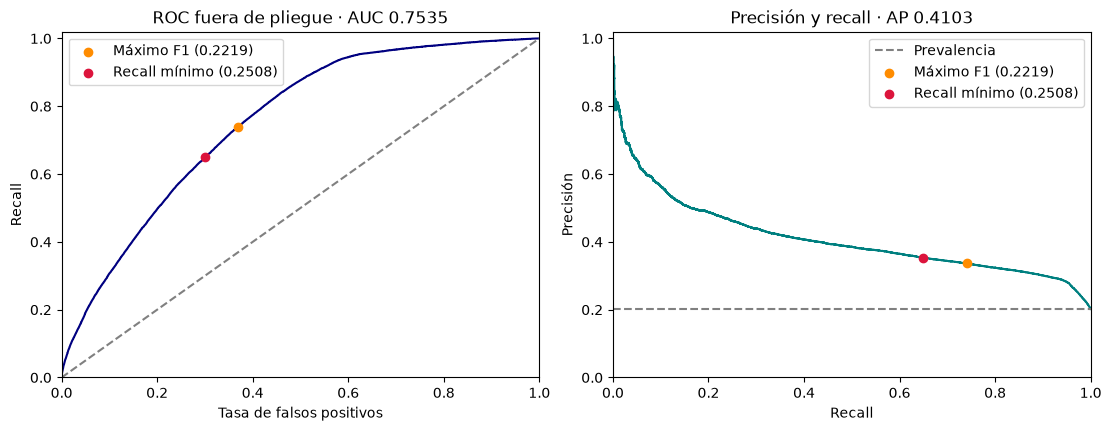

In [13]:
fpr, tpr, _ = roc_curve(y_mejorado, oof_preds_mejorado)
precision_pr, recall_pr, _ = precision_recall_curve(y_mejorado, oof_preds_mejorado)
fig, (roc, pr) = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
roc.plot(fpr, tpr, color="navy")
roc.plot([0, 1], [0, 1], linestyle="--", color="gray")
pr.plot(recall_pr, precision_pr, color="teal")
pr.axhline(y_mejorado.mean(), linestyle="--", color="gray", label="Prevalencia")
for clave, etiqueta, color in [("f1_optimo", "Máximo F1", "darkorange"),
                              ("recall_065", "Recall mínimo", "crimson")]:
    punto = umbrales[clave]
    corte = punto["umbral"]
    tasa_fp = (oof_preds_mejorado[y_mejorado == 0] >= corte).mean()
    leyenda = f"{etiqueta} ({corte:.4f})"
    roc.scatter(tasa_fp, punto["recall"], label=leyenda, color=color, zorder=3)
    pr.scatter(punto["recall"], punto["precision"], label=leyenda, color=color, zorder=3)
roc.set(title=f"ROC fuera de pliegue · AUC {res_mejorado['roc_auc']:.4f}",
        xlabel="Tasa de falsos positivos", ylabel="Recall")
pr.set(title=f"Precisión y recall · AP {res_mejorado['pr_auc']:.4f}",
       xlabel="Recall", ylabel="Precisión")
for eje in (roc, pr):
    eje.set(xlim=(0, 1), ylim=(0, 1.02))
    eje.legend()
plt.show()


## 7. Prueba temporal

Entrenamos con las citas hasta el 25 de mayo de 2016 inclusive y probamos con las posteriores. El catálogo categórico de la matriz se aplica con el mismo orden a ambos períodos. Para comparar la calidad del ranking mostramos ROC-AUC, PR-AUC, Lift@20 y Recall@20. Las métricas de clasificación almacenadas reutilizan los cortes F1 de la validación agrupada. Esos cortes también vieron citas posteriores al 25 de mayo en sus respectivos pliegues, por lo que esta prueba temporal se interpreta principalmente por sus métricas de ranking.


In [14]:
def evaluar_temporal(datos, X, y, categoricas, params, corte, nombre):
    es_train = datos["AppointmentDay"].le(pd.Timestamp(FECHA_CORTE_TEMPORAL)).to_numpy()
    X_train, X_test = X.loc[es_train].copy(), X.loc[~es_train].copy()
    for col in categoricas:
        categorias = X[col].cat.categories
        X_train[col] = pd.Categorical(X_train[col], categories=categorias)
        X_test[col] = pd.Categorical(X_test[col], categories=categorias)
    modelo = LGBMClassifier(**params).fit(X_train, y[es_train])
    probas = modelo.predict_proba(X_test)[:, 1]
    return calcular_metricas(y[~es_train], probas, nombre, corte)

temporal_base = evaluar_temporal(df_base, X_base, y_base, BASE_CATEGORICAS, params_base,
                                 res_base["umbral"], "Baseline")
temporal_mejorado = evaluar_temporal(df_mejorado, X_mejorado, y_mejorado, MEJOR_CATEGORICAS,
                                     mejores_params, umbral_f1, "Mejorado")
print(df["AppointmentDay"].le(pd.Timestamp(FECHA_CORTE_TEMPORAL)).value_counts()
      .rename(index={True: "Entrenamiento", False: "Prueba"}).to_string())
pd.DataFrame([temporal_base, temporal_mejorado])[["roc_auc", "pr_auc", "lift20", "recall20"]].round(4)


AppointmentDay
Entrenamiento    75278
Prueba           35243


,roc_auc,pr_auc,lift20,recall20
Baseline,0.7184,0.3189,1.7798,0.3560
Mejorado,0.7303,0.3458,1.8876,0.3775


## 8. Entrenamiento final y contrato de inferencia

Una vez calculadas las métricas OOF, ajustamos el estimador con todas las citas. Empaquetamos el orden de las 38 variables, los niveles categóricos, los valores iniciales para pacientes sin historial, los dos cortes y las métricas. El archivo de métricas y el modelo comparten los mismos resultados de esta ejecución.


In [15]:
modelo_final = LGBMClassifier(**mejores_params).fit(X_mejorado, y_mejorado)
categorias = {col: [str(v) for v in X_mejorado[col].cat.categories] for col in MEJOR_CATEGORICAS}
tasa_global = float(y_mejorado.mean())
temporal = {"corte": FECHA_CORTE_TEMPORAL, "baseline": temporal_base.to_dict(),
            "modelo_mejorado": temporal_mejorado.to_dict()}
payload = {
    "model": modelo_final, "target": "No-show", "positive_class": "No-show=True (1): el paciente no asistió",
    "features": FEATURES, "numeric_features": MEJOR_NUMERICAS, "categorical_features": MEJOR_CATEGORICAS,
    "categorical_categories": categorias, "global_no_show_rate": tasa_global,
    "feature_defaults": {"PriorVisits": 0, "PriorNoShows": 0, "PriorNoShowRate": tasa_global,
                         "HasHistory": 0, "DaysSinceLastVisit": None, "LastVisitNoShow": None},
    "history_mode": "cita", "threshold": umbral_f1, "threshold_recall_065": umbral_recall,
    "thresholds": umbrales, "trained_at": datetime.now().astimezone().isoformat(timespec="seconds"),
    "training_rows": len(X_mejorado), "training_patients": int(df_mejorado["PatientId"].nunique()),
    "lightgbm_version": lightgbm.__version__, "params": mejores_params,
    "metrics_oof": res_mejorado.to_dict(), "baseline_oof": res_base.to_dict(), "temporal": temporal,
    "nota": "La clase 1 representa inasistencia. Fijar las categorías antes de inferir. "
            "threshold_recall_065 maximiza la precisión OOF con recall de al menos 0.65.",
}
metricas_json = {
    "baseline_notebook_05": payload["baseline_oof"], "modelo_mejorado": payload["metrics_oof"],
    "mejora_absoluta": (res_mejorado - res_base).drop("umbral").to_dict(),
    "validacion_temporal": temporal, "umbrales": umbrales, "umbrales_baseline": umbrales_base,
    "protocolo": "GroupKFold(5) por PatientId. Umbrales OOF. Top 20 % con round(0.20 × n).",
    "generado_en": payload["trained_at"],
}


### Verificación antes de sustituir el artefacto

Serializamos y volvemos a cargar el candidato antes de publicarlo. Si hay un modelo vigente, comprobamos primero las categorías, los árboles y las probabilidades sobre las mismas 1.000 citas seleccionadas con semilla 42. Un cambio en los árboles, en la matriz de entrada o en la predicción interrumpe la exportación. La revisión del umbral se presenta por separado porque modifica decisiones de contacto incluso si el ranking se conserva.


In [16]:
muestra = X_mejorado.sample(n=1000, random_state=SEMILLA)

def verificar_equivalencia(anterior, candidato):
    for clave in ("features", "numeric_features", "categorical_features", "categorical_categories"):
        assert anterior[clave] == candidato[clave], f"Ha cambiado {clave}."
    publicado, nuevo = anterior["model"], candidato["model"]
    assert publicado.booster_.num_trees() == nuevo.booster_.num_trees() == 1050
    probas_antes = publicado.predict_proba(muestra)[:, 1]
    probas_despues = nuevo.predict_proba(muestra)[:, 1]
    diferencia = float(np.max(np.abs(probas_antes - probas_despues)))
    assert diferencia < 1e-9, f"Las predicciones difieren en {diferencia}."
    for arbol_anterior, arbol_nuevo in zip(publicado.booster_.dump_model()["tree_info"],
                                         nuevo.booster_.dump_model()["tree_info"], strict=True):
        assert arbol_anterior == arbol_nuevo, "Ha cambiado un árbol del modelo publicado."
    print(f"{len(muestra)} citas | diferencia máxima: {diferencia:.3g} | árboles: {nuevo.booster_.num_trees()}")
    for clave in ("threshold", "threshold_recall_065"):
        print(f"{clave}: {anterior[clave]:.8f} → {candidato[clave]:.8f}")
    metricas_antes = anterior.get("metrics_oof", anterior.get("metrics", {}))
    print(pd.DataFrame({"Anterior": metricas_antes, "Actual": candidato["metrics_oof"]})
          .dropna().round(6).to_string())

with TemporaryDirectory(dir=RUTA_MODELOS) as carpeta:
    etapa = Path(carpeta)
    joblib.dump(payload, etapa / RUTA_MODELO.name)
    candidato = joblib.load(etapa / RUTA_MODELO.name)
    if RUTA_MODELO.exists():
        verificar_equivalencia(joblib.load(RUTA_MODELO), candidato)
    escribir_json(etapa / RUTA_METRICAS.name, metricas_json)
    if EJECUTAR_OPTUNA:
        escribir_json(etapa / RUTA_PARAMS.name, mejores_params)
        (etapa / RUTA_PARAMS.name).replace(RUTA_PARAMS)
    (etapa / RUTA_MODELO.name).replace(RUTA_MODELO)
    (etapa / RUTA_METRICAS.name).replace(RUTA_METRICAS)
print(f"Guardados: {RUTA_MODELO} y {RUTA_METRICAS}")


1000 citas | diferencia máxima: 0 | árboles: 1050
threshold: 0.22190000 → 0.22192508
threshold_recall_065: 0.25080000 → 0.25082512
         Anterior    Actual
roc_auc  0.753501  0.753501
pr_auc   0.410332  0.410332
f1       0.462722  0.462754
lift20   2.014133  2.014000
Guardados: models\mejor_modelo_lgbm.joblib y models\metricas.json


## 9. Prueba de inferencia y decisión operativa

Tomamos una cita del conjunto como comprobación de la implementación. La probabilidad se calcula con el modelo recargado y las categorías guardadas. El resultado de esta fila comprueba la integración. Las métricas OOF son las que permiten valorar el rendimiento.


In [17]:
publicado = joblib.load(RUTA_MODELO)
cita = X_mejorado.iloc[[0]].loc[:, publicado["features"]].copy()
for col in publicado["categorical_features"]:
    niveles = publicado["categorical_categories"][col]
    cita[col] = pd.Categorical(cita[col], categories=niveles)
    assert cita[col].cat.categories.tolist() == niveles and cita[col].notna().all()
probabilidad = publicado["model"].predict_proba(cita)[0, 1]
priorizar = bool(probabilidad >= publicado["threshold_recall_065"])
assert 0 <= probabilidad <= 1
assert abs(probabilidad - modelo_final.predict_proba(X_mejorado.iloc[[0]])[0, 1]) < 1e-12
assert priorizar == bool(probabilidad >= umbrales["recall_065"]["umbral"])
print(f"Probabilidad de inasistencia: {probabilidad:.2%} | priorizar contacto: {priorizar}")


Probabilidad de inasistencia: 1.39% | priorizar contacto: False


## 10. ¿Qué decisión respaldan los resultados?

M1 exige identificar al menos el 65 % de las inasistencias. M2 exige que el grupo de mayor riesgo concentre al menos 1,50 veces la tasa global. Los datos proceden de Brasil en 2016. El traslado a otra red de atención requiere validación local. `SMS_received` registra una intervención previa y solo está disponible cuando ya se conoce su estado. Un uso anterior al envío requeriría reentrenar. La asociación observada no demuestra que el recordatorio evite una inasistencia. El equipo clínico conserva la decisión sobre el contacto y la cita.


In [18]:
recall_m1 = umbrales["recall_065"]["recall"]
lift_m2 = res_mejorado["lift20"]
print(f"M1 · recall {recall_m1:.2%} frente a 65 %: {'cumple' if recall_m1 >= 0.65 else 'pendiente'}")
print(f"M2 · Lift@20 {lift_m2:.4f} frente a 1.50: {'cumple' if lift_m2 >= 1.50 else 'pendiente'}")
print(f"El grupo priorizado reúne el {res_mejorado['recall20']:.2%} de las inasistencias OOF.")


M1 · recall 65.00% frente a 65 %: cumple
M2 · Lift@20 2.0140 frente a 1.50: cumple
El grupo priorizado reúne el 40.28% de las inasistencias OOF.
